# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

**Rules:** label every output, e.g. `print("T5a:", ...)` · use `random_state=42` for the split · written answers go in Markdown cells · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab05/Lab05.ipynb` by the deadline announced in class (11:59 PM PKT).

Name: Afzal Ali Ahmed  Roll No: 2024-SE-04

### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).

T1a: shape of full data: (20484, 11)
T1b: shape of gli: (796, 11)
T1c: summary statistics
              Age  Price_lakh
count  796.000000  796.000000
mean     6.445980   16.586237
std      3.107847    3.984407
min      2.000000    6.543210
25%      4.000000   13.500000
50%      6.000000   16.500000
75%      9.000000   19.500000
max     15.000000   30.000000
T1d: correlation(Age, Price_lakh) = -0.896


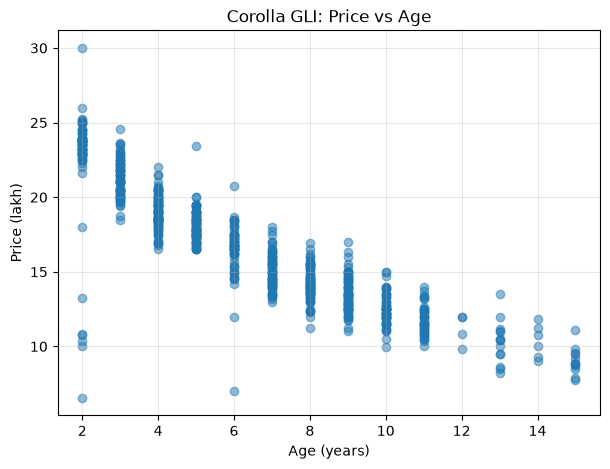

In [2]:

# (a) load
df = pd.read_csv("pakistan_used_cars_clean.csv")
print("T1a: shape of full data:", df.shape)

# (b) filter: Corolla GLI, Cash, Year 2005-2018, Price_lakh 5-40
gli = df[(df["Model"] == "Corolla GLI")
         & (df["Transaction Type"] == "Cash")
         & (df["Year"].between(2005, 2018))
         & (df["Price_lakh"].between(5, 40))].copy()
print("T1b: shape of gli:", gli.shape)

# (c) summary statistics
print("T1c: summary statistics")
print(gli[["Age", "Price_lakh"]].describe())

# (d) correlation
corr = gli["Age"].corr(gli["Price_lakh"])
print("T1d: correlation(Age, Price_lakh) =", round(corr, 3))

# (e) scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(gli["Age"], gli["Price_lakh"], alpha=0.5, color="tab:blue")
plt.title("Corolla GLI: Price vs Age")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh)")
plt.grid(alpha=0.3)
plt.show()




Yes, a straight line is a sensible model. The correlation between `Age` and `Price_lakh` is about **-0.896** (796 ads), which is a strong negative linear relationship: older cars are cheaper. The scatter plot agrees: the ads form a fairly straight, downward-sloping band with some spread around it and no obvious curve. Because there is only one input and the pattern is close to linear, a simple straight line fits well.

## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.

In [3]:

# (a) X must be 2-D (double brackets), y is 1-D
X = gli[["Age"]]
y = gli["Price_lakh"]
print("T2a: X shape:", X.shape, "| y shape:", y.shape)

# (b) 80 / 20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("T2b: X_train:", X_train.shape, "| X_test:", X_test.shape,
      "| y_train:", y_train.shape, "| y_test:", y_test.shape)

T2a: X shape: (796, 1) | y shape: (796,)
T2b: X_train: (636, 1) | X_test: (160, 1) | y_train: (636,) | y_test: (160,)


## Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.

In [4]:

# use training data only, plain NumPy arrays
x_tr = X_train["Age"].to_numpy()
y_tr = y_train.to_numpy()

# (a) means
x_bar = x_tr.mean()
y_bar = y_tr.mean()
print("T3a: x_bar =", round(x_bar, 4), "| y_bar =", round(y_bar, 4))

# (b) least squares formulas
b1 = np.sum((x_tr - x_bar) * (y_tr - y_bar)) / np.sum((x_tr - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
print("T3b: slope b1 =", round(b1, 4), "| intercept b0 =", round(b0, 4))

T3a: x_bar = 6.3821 | y_bar = 16.6533
T3b: slope b1 = -1.146 | intercept b0 = 23.9669





- **b1 ≈ -1.146 lakh per year (slope):** for every extra year of age, the expected price of a Corolla GLI falls by about 1.15 lakh (about Rs 115,000).
- **b0 ≈ 23.97 lakh (intercept):** the price the line predicts at age 0, i.e. a brand-new Corolla GLI. It is a starting point for the line; it is not reliable on its own because age 0 is outside the data we used (ages 2 to 15).

## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.

In [5]:

# (a) fit scikit-learn model on the training data
model = LinearRegression()
model.fit(X_train, y_train)
print("T4a: slope (coef_) =", model.coef_[0], "| intercept_ =", model.intercept_)

# (b) compare with the NumPy values from Task 3
print("T4b: slope matches     :", np.isclose(model.coef_[0], b1))
print("T4b: intercept matches :", np.isclose(model.intercept_, b0))

T4a: slope (coef_) = -1.1459556866983838 | intercept_ = 23.966900994196127
T4b: slope matches     : True
T4b: intercept matches : True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.

In [6]:

# (a) metrics by formula (test set)
y_pred = model.predict(X_test)
y_true = y_test.to_numpy()

mae  = np.mean(np.abs(y_true - y_pred))
mse  = np.mean((y_true - y_pred) ** 2)
rmse = np.sqrt(mse)
sse  = np.sum((y_true - y_pred) ** 2)
sst  = np.sum((y_true - y_true.mean()) ** 2)
r2   = 1 - sse / sst
print("T5a (formulas): MAE =", round(mae, 3), "| MSE =", round(mse, 3),
      "| RMSE =", round(rmse, 3), "| R2 =", round(r2, 3))

# (b) check with sklearn.metrics
print("T5b (sklearn) : MAE =", round(mean_absolute_error(y_test, y_pred), 3),
      "| MSE =", round(mean_squared_error(y_test, y_pred), 3),
      "| R2 =", round(r2_score(y_test, y_pred), 3))
print("T5b: formulas match sklearn:",
      np.isclose(mae, mean_absolute_error(y_test, y_pred)),
      np.isclose(mse, mean_squared_error(y_test, y_pred)),
      np.isclose(r2, r2_score(y_test, y_pred)))

# (c) train R2 vs test R2
r2_train = r2_score(y_train, model.predict(X_train))
r2_test = r2_score(y_test, y_pred)
print("T5c: train R2 =", round(r2_train, 3), "| test R2 =", round(r2_test, 3))

# (d) baseline: always predict the training mean
base_pred = np.full(len(y_test), y_train.mean())
base_mae = mean_absolute_error(y_test, base_pred)
base_r2 = r2_score(y_test, base_pred)
print("T5d: baseline MAE =", round(base_mae, 3), "| baseline R2 =", round(base_r2, 3))
print("T5d: model reduces the error by", round((1 - mae / base_mae) * 100, 1), "%")

T5a (formulas): MAE = 1.185 | MSE = 2.704 | RMSE = 1.644 | R2 = 0.845
T5b (sklearn) : MAE = 1.185 | MSE = 2.704 | R2 = 0.845
T5b: formulas match sklearn: True True True
T5c: train R2 = 0.79 | test R2 = 0.845
T5d: baseline MAE = 3.504 | baseline R2 = -0.006
T5d: model reduces the error by 66.2 %



- **MAE ≈ 1.19 lakh:** on average, the model's predicted price misses the real asking price by about 1.2 lakh rupees (about Rs 119,000), in the same unit as the price.
- **R² ≈ 0.85:** age alone explains about 85 % of the variation in Corolla GLI prices on unseen ads. R² is not "85 % accuracy"; it is the share of the price variation that the line explains.
- **Overfitting?** No. Train R² (about 0.79) is close to test R² (about 0.85), so the model is not memorising the training data. Test R² is slightly higher only because the 160 test ads happen to have a wider spread of prices, while the model's typical error is about the same on both sets (about 1.6–1.8 lakh). It does not mean the model is better on new data.
- **Baseline:** always guessing the average training price gives MAE ≈ 3.50 lakh and R² ≈ 0. Our model's MAE of 1.19 lakh is about two-thirds smaller, so it is clearly much better than guessing the average.

## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?

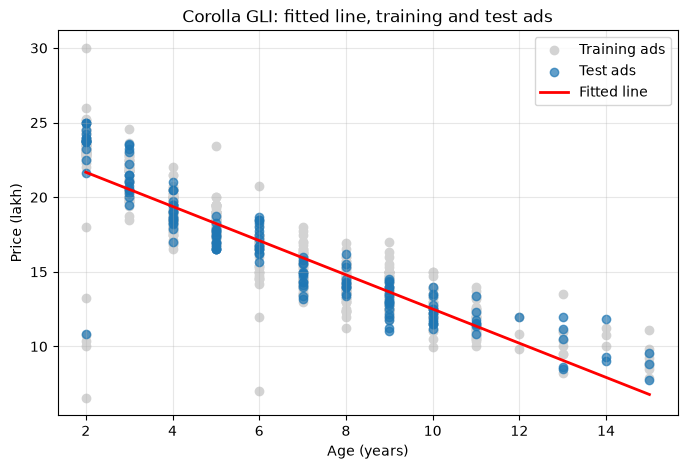

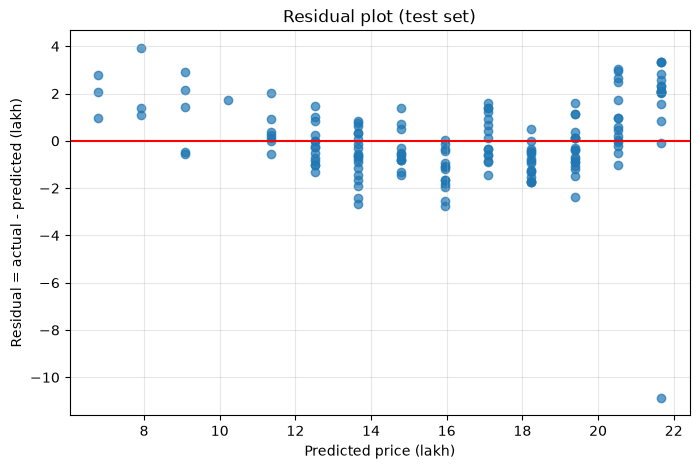

T6c: five largest errors
       Year  KMs Driven Registered City  Actual_price  Predicted_price  Abs_error
18857  2018         NaN         Unknown         10.80        21.674990  10.874990
20280  2006    220000.0       Islamabad         11.85         7.923521   3.926479
17363  2018         NaN         Unknown         25.00        21.674990   3.325010
18980  2018         NaN         Unknown         25.00        21.674990   3.325010
16557  2018       300.0         Unknown         25.00        21.674990   3.325010


In [7]:

# (a) training ads, test ads and the fitted line
plt.figure(figsize=(8, 5))
plt.scatter(X_train["Age"], y_train, color="lightgrey", label="Training ads")
plt.scatter(X_test["Age"], y_test, color="tab:blue", alpha=0.7, label="Test ads")
age_line = pd.DataFrame({"Age": np.linspace(gli["Age"].min(), gli["Age"].max(), 100)})
plt.plot(age_line["Age"], model.predict(age_line), color="red", linewidth=2, label="Fitted line")
plt.title("Corolla GLI: fitted line, training and test ads")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# (b) residual plot (test set)
residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.7, color="tab:blue")
plt.axhline(0, color="red")
plt.title("Residual plot (test set)")
plt.xlabel("Predicted price (lakh)")
plt.ylabel("Residual = actual - predicted (lakh)")
plt.grid(alpha=0.3)
plt.show()

# (c) five test ads with the largest absolute error
errors = gli.loc[X_test.index, ["Year", "KMs Driven", "Registered City"]].copy()
errors["Actual_price"] = y_test
errors["Predicted_price"] = y_pred
errors["Abs_error"] = np.abs(y_test - y_pred)
print("T6c: five largest errors")
print(errors.sort_values("Abs_error", ascending=False).head(5).to_string())




- **Residual plot:** there is no funnel: the spread is roughly similar for cheap and mid-priced predictions (a few outliers aside). There is a *slight curve*: residuals are mostly positive for the oldest cars (low predicted price), mostly negative in the middle, and positive again for the newest cars. So the real price-vs-age relationship bends a little, but the straight line is still a reasonable model. The vertical stripes appear because `Age` is a whole number, so the model gives only a few different predicted prices.
- **Largest errors:** these are mostly **data mistakes, not model mistakes**. The biggest is a 2018 Corolla GLI listed at only **10.8 lakh** while the model predicts about **21.7 lakh** (an error of about 10.9 lakh). Similar 2018 cars are listed at about 25 lakh, so this price is probably a typing error or a down payment instead of the full price. Several other large errors are also 2018 cars (many with missing `KMs Driven` and an `Unknown` city) priced about 3.3 lakh above the prediction, which comes from the model using age only and ignoring mileage and condition. The 2006 car with 220,000 km is a normal model limitation: its price differs from the line by about 3.9 lakh. Because regression squares the errors, one wrong ad like the 10.8 lakh listing can pull on the fitted line.

## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?

In [8]:

# (a) predict 2018, 2015 and 2010 (age = 2020 - year)
years = [2018, 2015, 2010]
new_cars = pd.DataFrame({"Age": [2020 - yr for yr in years]})
preds = model.predict(new_cars)
for yr, p in zip(years, preds):
    print("T7a:", yr, "Corolla GLI ->", round(p, 2), "lakh")

# (b) a 1995 car (age 25) is far outside the data (ages 2-15)
p_1995 = model.predict(pd.DataFrame({"Age": [25]}))[0]
print("T7b: 1995 Corolla GLI (age 25) ->", round(p_1995, 2), "lakh")

T7a: 2018 Corolla GLI -> 21.67 lakh
T7a: 2015 Corolla GLI -> 18.24 lakh
T7a: 2010 Corolla GLI -> 12.51 lakh
T7b: 1995 Corolla GLI (age 25) -> -4.68 lakh





- **(a)** A 2018 car (age 2) ≈ **21.7 lakh**, a 2015 car (age 5) ≈ **18.2 lakh**, and a 2010 car (age 10) ≈ **12.5 lakh**. These are sensible because ages 2 to 10 lie inside the range the model learned from.
- **(b)** The 1995 car (age 25) gives about **-4.7 lakh**, which is **not believable**: a price cannot be negative. This is **extrapolation**. The model was trained on ages 2 to 15 only, and a straight line keeps going down forever, but real prices flatten out for very old cars. The model must only be used inside the range of ages it has seen.

## Task 8 · Reflection (Markdown cell)
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.




I loaded the cleaned OLX data and filtered it to Corolla GLI cash ads, then chose `Age` as X (2-D) and `Price_lakh` as y and split the data 80/20 with `random_state=42`. I computed the least squares slope and intercept in NumPy on the training data, confirmed them with scikit-learn's `LinearRegression`, and then evaluated the model on the test set with MAE, MSE, RMSE and R², compared with a baseline and checked the residuals. The model is judged on the test set because those ads were never seen during training; scoring on the training data would give a flattering number and hide overfitting. To a car buyer I would quote the **MAE (about 1.2 lakh)**, because it says in plain rupees how far off the estimate typically is, while R² is harder to explain. One limitation of using age alone is that it ignores other things that change price (mileage, condition, city, fuel type, the exact variant), so two cars of the same age but very different condition get the same prediction, and it cannot be trusted outside the ages it learned from.